# Scaling numerical features

Features measured in different units come in numbers of very different sizes: a wine's proline content goes up to 1,680 milligrams per litre, its colour hue stays below 2. Some models compare those numbers directly, and for them the feature with the biggest numbers decides, whatever its importance. **Scaling** puts every feature on a comparable scale.

## The words

The vocabulary is used inconsistently, so it is worth being explicit about which transformation is meant:

- **Scaling** is the general word, and scikit-learn calls all these transformers *scalers*.
- **Normalisation** often means **min-max scaling**, to a range such as 0 to 1. But torchvision's `transforms.Normalize` and Keras' `Normalization` layer standardise, and scikit-learn's `Normalizer` does something else again: it scales each *row*, not each column (see the end of this notebook).
- **Standardisation** subtracts the mean and divides by the standard deviation, so that the column has a mean of 0 and a standard deviation of 1 (the *z-score*).

All of them, except `Normalizer`, transform each column on its own with a straight line, a shift and a stretch. They change the units, not the shape of the distribution or the order of the values: a skewed column is still skewed after scaling ([Skewed distributions and the log transform](deep-dives/skewed_distributions.ipynb)).

## Why: a distance

Three people, described by their age and their yearly income:

In [ ]:
import pandas as pd

people = pd.DataFrame({"age": [25, 62, 26], "income": [30_000, 30_500, 33_000]}, index=["A", "B", "C"])
people

,age,income
A,25,30000
B,62,30500
C,26,33000


Which person is most similar to A? B has almost the same income and is 37 years older; C is one year older and earns 3,000 more. The Euclidean distance, used by k-nearest neighbours and many other models, adds up the squared differences of the features:

In [ ]:
import numpy as np


def distances_from_a(table):
    return np.sqrt(((table - table.loc["A"]) ** 2).sum(axis=1)).drop("A")


distances_from_a(people).round(1)

B     501.4
C    3000.0
dtype: float64

B is "closer" to A than C is, because 500 euros count as 500 and 37 years count as 37. The income, a number in thousands, decides alone. Standardising measures each feature in its own standard deviations. The standard deviations come from a whole table of people, not from these three; across a population, ages vary by about 15 years and incomes by about 10,000 euros (subtracting the mean, the other half of standardising, doesn't change distances):

In [ ]:
typical_spread = pd.Series({"age": 15, "income": 10_000})
distances_from_a(people / typical_spread).round(2)

B    2.47
C    0.31
dtype: float64

Now C is the nearest, as intuition says. Neither answer is "true": scaling decides how much each feature counts in the distance, and without it the units decide, which is never a reason.

## The scalers

A column of incomes in thousands, with one person far richer than the rest:

In [ ]:
incomes = pd.DataFrame({"income": [21, 24, 26, 27, 29, 31, 33, 35, 38, 250]})

scikit-learn's four scalers for features, each fitted on this column:

| Scaler | Formula | Result |
| --- | --- | --- |
| `MinMaxScaler` | $(x - \min) / (\max - \min)$ | between 0 and 1 |
| `StandardScaler` | $(x - \text{mean}) / \text{standard deviation}$ | mean 0, standard deviation 1 |
| `RobustScaler` | $(x - \text{median}) / \text{interquartile range}$ | median 0, the middle half spans 1 |
| `MaxAbsScaler` | $x / \max \lvert x \rvert$ | between −1 and 1, zeros stay zeros |

In [ ]:
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler, RobustScaler, StandardScaler

scalers = {"min-max": MinMaxScaler(), "standard": StandardScaler(), "robust": RobustScaler(), "max-abs": MaxAbsScaler()}
pd.DataFrame({name: scaler.fit_transform(incomes).ravel() for name, scaler in scalers.items()}, index=incomes["income"]).round(2)

,min-max,standard,robust,max-abs
income,,,,
21,0.00,-0.46,-1.09,0.08
24,0.01,-0.41,-0.73,0.10
26,0.02,-0.38,-0.48,0.10
27,0.03,-0.37,-0.36,0.11
29,0.03,-0.34,-0.12,0.12
31,0.04,-0.31,0.12,0.12
33,0.05,-0.28,0.36,0.13
35,0.06,-0.25,0.61,0.14
38,0.07,-0.20,0.97,0.15


- **Min-max** puts the extreme value at 1 and squeezes the nine others between 0 and 0.07.
- **Standard** isn't protected either: the extreme value inflates the standard deviation, so the nine others are squeezed between −0.5 and −0.2. The mean and the standard deviation are both pulled by one extreme value ([Outliers and capped values](deep-dives/outliers.ipynb)).
- **Robust** uses the median and the interquartile range, which the extreme value doesn't move: the nine ordinary incomes spread between about −1.1 and 1. The extreme value is still there, now at about 27: a robust scaler scales the ordinary values well, it doesn't remove outliers.
- **Max-abs** only divides, so zeros stay zeros. It is meant for sparse data, such as word counts, where subtracting anything would turn the zeros, most of the data, into other numbers.

None changes the order of the values, and none makes the column less skewed.

## Which models need scaling

The wine dataset: 178 Italian wines from three cultivars, with 13 chemical measurements. Their ranges:

In [ ]:
from sklearn.datasets import load_wine

X, y = load_wine(return_X_y=True, as_frame=True)
X.agg(["min", "max"]).T.sort_values("max").round(2)

,min,max
nonflavanoid_phenols,0.13,0.66
hue,0.48,1.71
ash,1.36,3.23
proanthocyanins,0.41,3.58
total_phenols,0.98,3.88
od280/od315_of_diluted_wines,1.27,4.00
flavanoids,0.34,5.08
malic_acid,0.74,5.80
color_intensity,1.28,13.00
alcohol,11.03,14.83


From nonflavanoid phenols, below 1, to proline, up to 1,680. Two of them, proline and hue, are enough to see what a k-nearest-neighbours classifier makes of it. The figure is adapted from scikit-learn's example [Importance of Feature Scaling](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html) (BSD-3-Clause licence, Copyright (c) 2007-2024 The scikit-learn developers. All rights reserved):

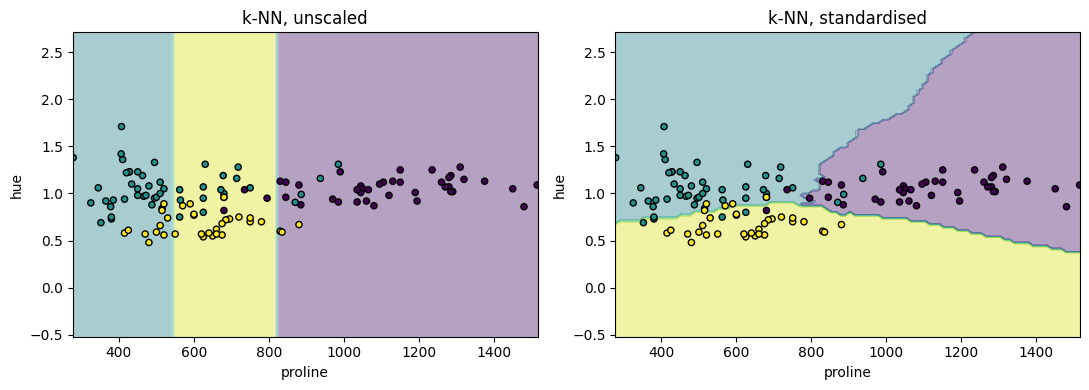

In [ ]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
two_features = ["proline", "hue"]
classifiers = {
    "unscaled": KNeighborsClassifier(n_neighbors=20),
    "standardised": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=20)),
}
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, (name, classifier) in zip(axes, classifiers.items()):
    classifier.fit(X_train[two_features], y_train)
    DecisionBoundaryDisplay.from_estimator(classifier, X_train[two_features], response_method="predict", alpha=0.4, ax=axis)
    axis.scatter(X_train["proline"], X_train["hue"], c=y_train, edgecolor="k", s=20)
    axis.set_title(f"k-NN, {name}")
figure.tight_layout()

Unscaled, the boundaries between the cultivars are vertical lines: only proline matters, because a difference of 0.5 in hue is nothing next to differences of hundreds in proline. Standardised, both features shape the boundaries. The same models, on all 13 features, unscaled and standardised, by 5-fold cross-validation on the training rows:

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {
    "k-nearest neighbours": KNeighborsClassifier(),
    "support vector machine": SVC(),
    "logistic regression": LogisticRegression(max_iter=10_000),
    "decision tree": DecisionTreeClassifier(random_state=0),
    "random forest": RandomForestClassifier(random_state=0),
}
pd.DataFrame({
    "unscaled": {name: cross_val_score(model, X_train, y_train, cv=5).mean() for name, model in models.items()},
    "standardised": {name: cross_val_score(make_pipeline(StandardScaler(), model), X_train, y_train, cv=5).mean()
                     for name, model in models.items()},
}).round(3)

,unscaled,standardised
k-nearest neighbours,0.710,0.959
support vector machine,0.677,0.992
logistic regression,0.951,0.984
decision tree,0.894,0.894
random forest,0.975,0.975


Three groups of models:

- **Models built on distances** need scaling: k-nearest neighbours goes from 71% to 96% accuracy, and the support vector machine, whose default kernel is a function of the distance, from 68% to 99% ([k-nearest neighbours](../supervised-learning/algorithms/neighbours/knn.ipynb), [Support vector machines](../supervised-learning/deep-dives/svm.ipynb)). So do k-means and principal component analysis, which looks for the directions of largest variance, and without scaling finds the features with the largest numbers (Unsupervised learning *(coming)*).
- **Models with a penalty or fitted by gradient descent** are affected. scikit-learn's logistic regression is regularised: it adds the size of the weights to what it minimises, and the size of a weight depends on the units of its feature, so scaling changes which features the penalty restrains ([Regularisation](../supervised-learning/ml-fundamentals/regularization.ipynb)). Models fitted by gradient descent, neural networks among them, converge much more slowly on unscaled features ([Gradient descent](../supervised-learning/ml-fundamentals/gradient_descent.ipynb)).
- **Trees** don't care: the tree and the forest get exactly the same accuracy. A tree splits each feature at a threshold, and any transformation that keeps the order of the values keeps the same splits.

Plain least squares, with no penalty, is a fourth case: its predictions are the same with or without scaling, because each weight simply absorbs the units of its feature ([California housing, step by step](../supervised-learning/basic-workflows/california_by_hand.ipynb)). Scaling still makes its weights comparable with each other.

## Fitted on the training rows

A scaler learns from the data: the minimum and maximum, or the mean and standard deviation, of each column. So it is fitted on the training rows only, inside the model's pipeline, as in the cross-validation above, and applied unchanged to new rows ([Where data preparation ends](where_preparation_ends.ipynb)). A consequence, with min-max scaling: new rows can fall outside the range seen in training:

In [ ]:
min_max = MinMaxScaler().set_output(transform="pandas").fit(X_train)
test_scaled = min_max.transform(X_test)
pd.Series({"smallest test value": round(test_scaled.min().min(), 3), "largest test value": round(test_scaled.max().max(), 3),
           "test values above 1": (test_scaled > 1).sum().sum(), "test values below 0": (test_scaled < 0).sum().sum()}, dtype=object)

smallest test value   -0.003
largest test value     1.394
test values above 1        8
test values below 0        1
dtype: object

Nine test values fall outside [0, 1], one of them at 1.39. That is correct behaviour, not an error: the test rows are scaled with what was learned from the training rows. If a model needs the range strictly respected, `MinMaxScaler(clip=True)` clips new values to it.

## Scaling the target *(deep dive)*

The target of a regression can be scaled too. It matters for models whose settings are in the units of the target. A support vector machine for regression ignores errors smaller than `epsilon` (0.1 by default) and limits how far it bends to fit with `C` (1 by default); with a target in the hundreds, those defaults are far too small. `TransformedTargetRegressor` scales the target before training and turns the predictions back into the original units. On scikit-learn's diabetes data, with the features in their original units ([Diabetes progression](../supervised-learning/basic-workflows/deep-dives/diabetes_progression.ipynb)):

In [ ]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.datasets import load_diabetes
from sklearn.svm import SVR

X_diabetes, y_diabetes = load_diabetes(return_X_y=True, as_frame=True, scaled=False)
X_diabetes_train, X_diabetes_test, y_diabetes_train, y_diabetes_test = train_test_split(
    X_diabetes, y_diabetes, test_size=0.25, random_state=42)
support_vector_regression = make_pipeline(StandardScaler(), SVR())
with_scaled_target = TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), SVR()), transformer=StandardScaler())
pd.Series({
    "target as it is": cross_val_score(support_vector_regression, X_diabetes_train, y_diabetes_train, cv=5).mean(),
    "target standardised": cross_val_score(with_scaled_target, X_diabetes_train, y_diabetes_train, cv=5).mean(),
}).round(3).rename("R²")

target as it is        0.091
target standardised    0.389
Name: R², dtype: float64

The same model explains 9% of the variance with the target as it is, and 39% with it standardised: the defaults now fit the scale of the target. The predictions of `with_scaled_target` are in the original units; `TransformedTargetRegressor` calls the scaler's `inverse_transform`.

For many other models, scaling the target changes nothing. A k-nearest-neighbours regressor predicts the average target of the neighbours, and the average of scaled targets, scaled back, is the same average; a plain linear regression scales its weights along with the target. The exceptions are models with a setting in the target's units, like the SVR above, or a Lasso and its `alpha`. Neural networks are the other common case where it helps: their training is more stable with a target of the order of 1. A logarithm of the target is a different transformation, for a different purpose ([Skewed distributions](deep-dives/skewed_distributions.ipynb)).

## Scaling rows: `Normalizer` *(deep dive)*

scikit-learn's `Normalizer` is not a scaler of columns. It divides each **row** by its length, so that every row becomes a vector of length 1:

In [ ]:
from sklearn.preprocessing import Normalizer

word_counts = pd.DataFrame({"model": [2, 20], "data": [1, 10], "cat": [0, 1]}, index=["short text", "long text"])
pd.DataFrame(Normalizer().fit_transform(word_counts), index=word_counts.index, columns=word_counts.columns).round(3)

,model,data,cat
short text,0.894,0.447,0.000
long text,0.894,0.447,0.045


The long text uses each word ten times as often as the short one, except for one more "cat"; once normalised, the two rows are almost identical, because only the proportions are left. That is what's wanted when the direction of a row matters more than its size: word counts of documents of different lengths, or vectors compared by the cosine of their angle (cosine similarity), as embeddings are. It learns nothing from the data, since each row is scaled on its own. For images, which are scaled neither like a table nor row by row, see [Scaling images](deep-dives/scaling_images.ipynb).